device: cuda
train=2944 val=736 test=3669
lr=0.001 ep1: val acc @96/160/224 = [np.float64(0.4253), np.float64(0.6753), np.float64(0.7337)]
lr=0.001 ep2: val acc @96/160/224 = [np.float64(0.4524), np.float64(0.731), np.float64(0.8098)]
lr=0.001 ep3: val acc @96/160/224 = [np.float64(0.4701), np.float64(0.7432), np.float64(0.803)]
lr=0.0003 ep1: val acc @96/160/224 = [np.float64(0.4688), np.float64(0.6766), np.float64(0.7391)]
lr=0.0003 ep2: val acc @96/160/224 = [np.float64(0.4959), np.float64(0.6875), np.float64(0.7582)]
lr=0.0003 ep3: val acc @96/160/224 = [np.float64(0.5204), np.float64(0.7296), np.float64(0.7731)]
lr=0.0003 ep4: val acc @96/160/224 = [np.float64(0.519), np.float64(0.7147), np.float64(0.7514)]
lr=0.0003 ep5: val acc @96/160/224 = [np.float64(0.5448), np.float64(0.7554), np.float64(0.803)]
lr=0.0003 ep6: val acc @96/160/224 = [np.float64(0.5448), np.float64(0.7704), np.float64(0.8166)]
lr=0.0003 ep7: val acc @96/160/224 = [np.float64(0.5299), np.float64(0.7704), np.fl

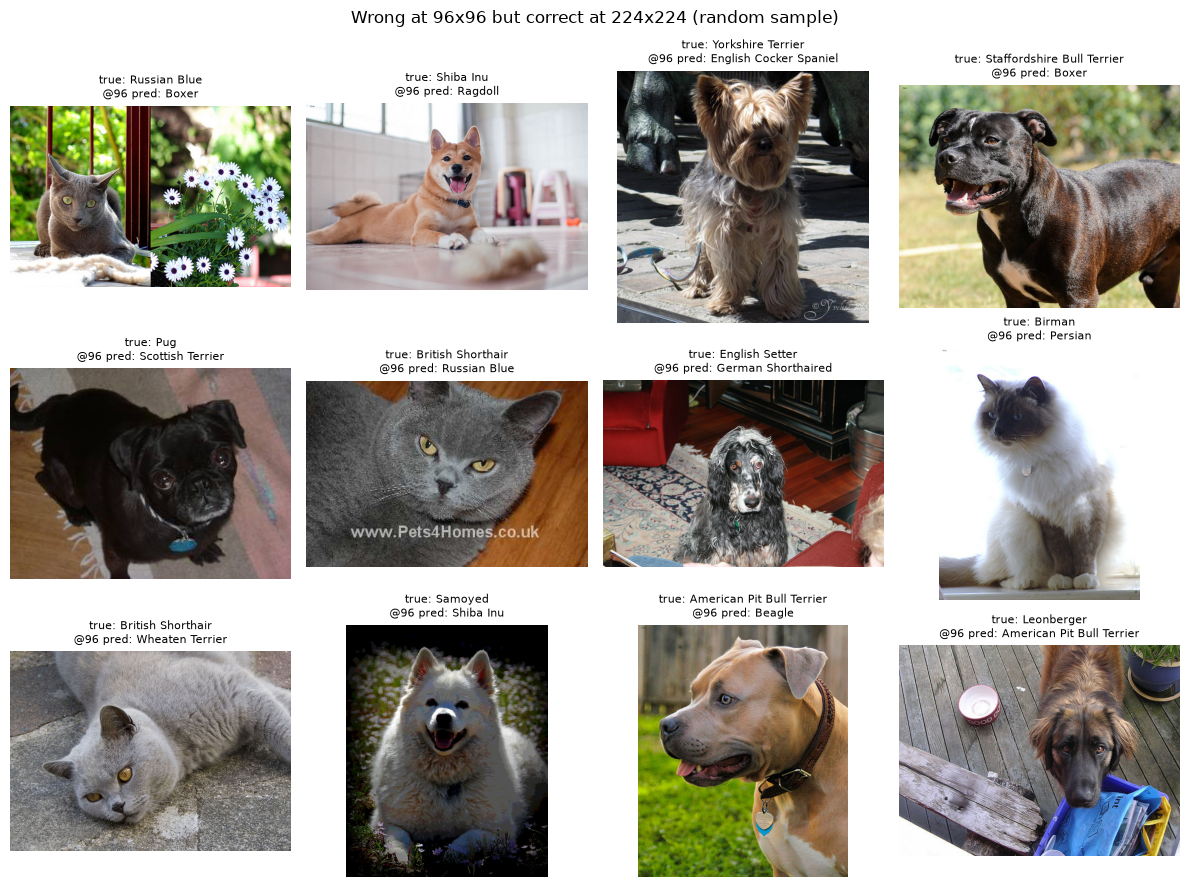

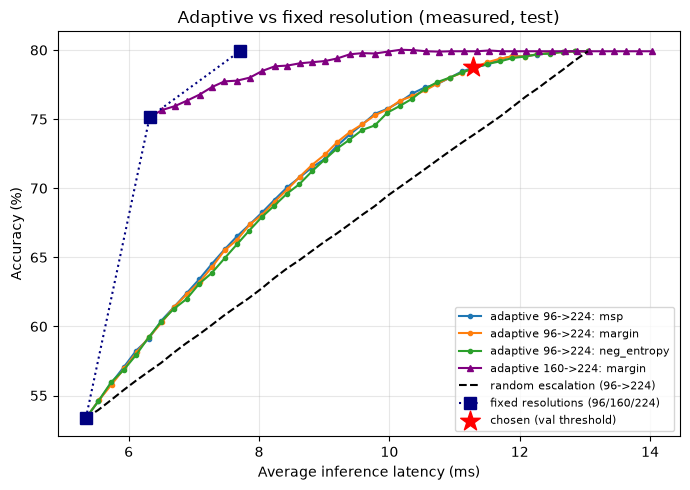

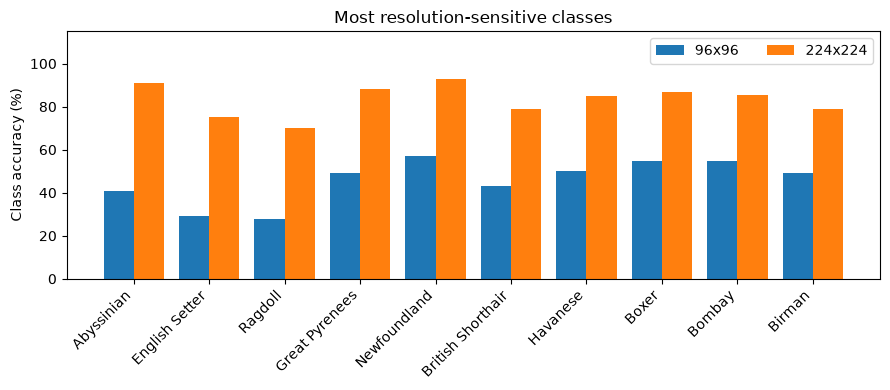

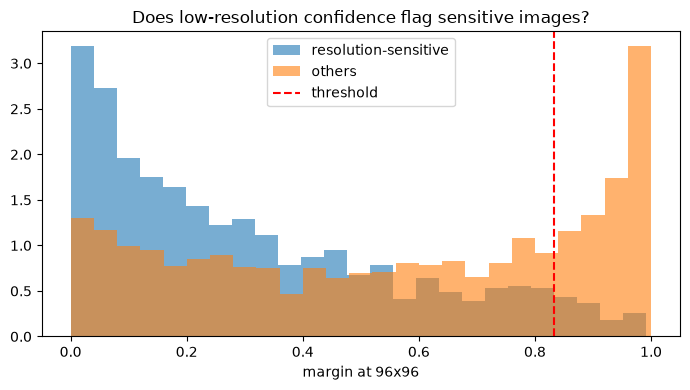

In [1]:
# %% [markdown]
# # Project 3: Input-Dependent Image Resolution Selection (نسخة مصحّحة)
# MobileNetV3-Small واحد، Oxford-IIIT Pet، 37 كلاس.
# السياسة: كل صورة تمر على 96x96 أولاً، وإذا الثقة منخفضة نعيد الصورة الأصلية على 224x224 بنفس الموديل.
# القواعد: الـ test لا نلمسه إلا في التقييم النهائي، والعتبة من الـ validation فقط، والـ latency على CPU ثابت.

# %% الإعدادات
import os, time, json, random
import numpy as np, pandas as pd, torch, torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader, Subset, Dataset
from sklearn.metrics import roc_auc_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # للتدريب وحساب الـ logits فقط
NUM_THREADS = 1          # موديل صغير: thread واحد يعطي قياس أثبت (غيّره لـ 4 إذا تبي وثبّته)
NUM_WORKERS = 2          # على ويندوز لو صار خطأ خله 0
FORCE_RETRAIN = False    # True = يعيد التدريب حتى لو فيه checkpoint
HEAD_EPOCHS, FULL_EPOCHS = 3, 20
N_BENCH, REPEATS = 300, 5   # حجم عيّنة قياس الـ latency وعدد التكرارات

DATA_ROOT, CKPT_DIR, OUT_DIR = "data", "checkpoints", "results_res"
for d in (CKPT_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

RES = [96, 160, 224]
LOW, MID, HIGH = RES
print("device:", DEVICE)

# %% البيانات (تحميل Oxford-IIIT Pet + split ثابت)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
norm = transforms.Normalize(MEAN, STD)

def eval_tf(r):
    # التصغير يتم من الصورة الأصلية مباشرة (وليس من نسخة 224)
    return transforms.Compose([transforms.Resize((r, r)), transforms.ToTensor(), norm])

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), norm])

def pets(split, tf):
    return datasets.OxfordIIITPet(DATA_ROOT, split=split, target_types="category",
                                  transform=tf, download=True)

ds_train_aug = pets("trainval", train_tf)

if os.path.exists("split.pt"):
    sp = torch.load("split.pt"); train_idx, val_idx = sp["train"], sp["val"]
else:
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(ds_train_aug), generator=g).tolist()
    n_val = int(0.2 * len(perm)); val_idx, train_idx = perm[:n_val], perm[n_val:]
    torch.save({"train": train_idx, "val": val_idx}, "split.pt")

train_set = Subset(ds_train_aug, train_idx)
val_sets = {r: Subset(pets("trainval", eval_tf(r)), val_idx) for r in RES}
test_sets = {r: pets("test", eval_tf(r)) for r in RES}
CLASSES = test_sets[HIGH].classes
print(f"train={len(train_set)} val={len(val_idx)} test={len(test_sets[HIGH])}")

# %% الموديل + fine-tuning بدقات متعددة (دقة عشوائية لكل batch)
def build():
    m = models.mobilenet_v3_small(weights="DEFAULT")
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 37)
    return m, m.classifier

@torch.no_grad()
def get_logits(model, ds, device=DEVICE, bs=128):
    model.eval().to(device)
    outs, ys = [], []
    for x, y in DataLoader(ds, batch_size=bs, num_workers=NUM_WORKERS):
        outs.append(model(x.to(device)).float().cpu()); ys.append(y)
    return torch.cat(outs), torch.cat(ys).numpy()

# اسم جديد (v2) عشان ما نستخدم checkpoint قديم ضعيف بالغلط
CKPT = f"{CKPT_DIR}/mnv3_multires_v2.pt"

def train_model():
    if os.path.exists(CKPT) and not FORCE_RETRAIN:
        print("checkpoint موجود، نتخطى التدريب"); return
    model, head = build(); model.to(DEVICE)
    loader = DataLoader(train_set, batch_size=64, shuffle=True,
                        num_workers=NUM_WORKERS, drop_last=True)
    crit, best = nn.CrossEntropyLoss(), 0.0

    def val_mean_acc():
        accs = []
        for r in RES:
            lg, yv = get_logits(model, val_sets[r]); accs.append((lg.argmax(1).numpy() == yv).mean())
        return float(np.mean(accs)), accs

    def phase(params, lr, epochs, backbone_frozen):
        nonlocal best
        opt = torch.optim.AdamW(list(params), lr=lr)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(loader))
        for ep in range(epochs):
            model.train()
            if backbone_frozen:
                model.eval(); head.train()      # الـ BatchNorm في الـ backbone ما يتغير وهو مجمّد
            for x, y in loader:
                r = random.choice(RES)                       # دقة عشوائية لكل batch
                if r != HIGH:
                    x = F.interpolate(x, size=(r, r), mode="bilinear", antialias=True, align_corners=False)
                x, y = x.to(DEVICE), y.to(DEVICE)
                opt.zero_grad(); crit(model(x), y).backward(); opt.step(); sched.step()
            m_acc, accs = val_mean_acc()
            print(f"lr={lr} ep{ep+1}: val acc @96/160/224 = {[round(a,4) for a in accs]}")
            if m_acc > best:
                best = m_acc; torch.save(model.state_dict(), CKPT)

    for p in model.parameters(): p.requires_grad = False
    for p in head.parameters(): p.requires_grad = True
    phase(head.parameters(), 1e-3, HEAD_EPOCHS, backbone_frozen=True)
    for p in model.parameters(): p.requires_grad = True
    phase(model.parameters(), 3e-4, FULL_EPOCHS, backbone_frozen=False)
    print("best mean val acc:", best)

train_model()
model, _ = build()
model.load_state_dict(torch.load(CKPT, map_location="cpu")); model.eval()

# %% logits لكل دقة (validation للاختيار، test للتقييم النهائي)
LG, Y = {"val": {}, "test": {}}, {}
for r in RES:
    LG["val"][r], Y["val"] = get_logits(model, val_sets[r])
    LG["test"][r], Y["test"] = get_logits(model, test_sets[r])
P = {s: {r: LG[s][r].argmax(1).numpy() for r in RES} for s in LG}
for r in RES:
    print(f"{r}x{r}: VAL acc={np.mean(P['val'][r]==Y['val']):.4f}")
# دقة الـ test تُستخدم فقط في التقرير النهائي، لا لاختيار أي شي

# %% قياس الـ latency (CPU، batch=1) - صور محمّلة مسبقاً + قياس متبادل بين الدقات
@torch.inference_mode()
def benchmark_latency(model, ds_by_res, warmup=30):
    torch.set_num_threads(NUM_THREADS)
    model = model.eval().to("cpu")
    idx = np.random.RandomState(SEED).choice(len(val_idx), N_BENCH, replace=False)
    # نحمّل الصور في الذاكرة أولاً: ما نقيس قراءة الصور ولا تغيير حجمها
    pool = {r: torch.stack([ds_by_res[r][int(i)][0] for i in idx]).unsqueeze(1) for r in RES}
    for r in RES:                                    # warm-up لكل شكل مدخل
        for i in range(warmup):
            model(pool[r][i % N_BENCH])
    ts = {r: [] for r in RES}
    for _ in range(REPEATS):
        for i in range(N_BENCH):
            for r in RES:                            # تبادل الدقات: أي بطء مؤقت للجهاز يصيب الكل بالتساوي
                t0 = time.perf_counter(); model(pool[r][i])
                ts[r].append((time.perf_counter() - t0) * 1000)
    return {r: np.array(ts[r]) for r in RES}

LAT_FILE = f"{OUT_DIR}/latency_pool_v2.npz"
if os.path.exists(LAT_FILE):
    z = np.load(LAT_FILE); LATP = {r: z[str(r)] for r in RES}
else:
    print("قياس الـ latency... لا تشغل شي ثاني على الجهاز")
    LATP = benchmark_latency(model, val_sets)
    np.savez(LAT_FILE, **{str(r): LATP[r] for r in RES})
for r in RES:
    print(f"{r}x{r}: mean={LATP[r].mean():.2f}ms median={np.median(LATP[r]):.2f}ms "
          f"p95={np.percentile(LATP[r],95):.2f}ms")

# نفس توزيع الـ latency لـ val و test (كان قبل كذا يُقاس مرتين بظروف مختلفة فيطلع غير متسق)
_rng = np.random.RandomState(SEED)
T = {s: {r: _rng.choice(LATP[r], size=n) for r in RES}
     for s, n in (("val", len(Y["val"])), ("test", len(Y["test"])))}

# عدد العمليات (اختياري): pip install fvcore
try:
    from fvcore.nn import FlopCountAnalysis
    FLOPS = {r: FlopCountAnalysis(model.cpu().eval(), torch.randn(1, 3, r, r)).total() / 1e6 for r in RES}
    print("MFLOPs:", {r: round(v, 1) for r, v in FLOPS.items()})
except Exception as e:
    FLOPS = None; print("تخطينا FLOPs:", type(e).__name__, "(نفّذ: pip install fvcore)")

# %% مقاييس الثقة ودوال السياسة
def scores(logits):
    p = torch.softmax(logits, 1); top2 = p.topk(2, dim=1).values
    ent = -(p * torch.log(p + 1e-12)).sum(1)
    return {"msp": top2[:, 0].numpy(), "margin": (top2[:, 0] - top2[:, 1]).numpy(),
            "neg_entropy": (-ent).numpy()}                 # الأكبر = أكثر ثقة

CRITERIA = ["msp", "margin", "neg_entropy"]
S = {s: {r: scores(LG[s][r]) for r in RES} for s in LG}

def qthr(score, q):
    return -np.inf if q == 0 else (np.inf if q == 1 else float(np.quantile(score, q)))

def evaluate_at(esc, p_low, p_high, y, t_low, t_high):
    """الصورة المصعّدة تدفع زمن الدقة المنخفضة + زمن الدقة العالية"""
    pred = np.where(esc, p_high, p_low); lat = t_low + esc * t_high
    return dict(acc=(pred == y).mean(), mean_lat=lat.mean(),
                p95_lat=np.percentile(lat, 95), esc_frac=esc.mean())

def sweep(score, p_low, p_high, y, t_low, t_high, n=41):
    return pd.DataFrame([dict(thr=qthr(score, q),
        **evaluate_at(score < qthr(score, q), p_low, p_high, y, t_low, t_high)) for q in np.linspace(0, 1, n)])

def random_baseline(frac, p_low, p_high, y, t_low, t_high, reps=50):
    rs = np.random.RandomState(SEED)
    res = [evaluate_at(rs.rand(len(y)) < frac, p_low, p_high, y, t_low, t_high) for _ in range(reps)]
    return {k: float(np.mean([r[k] for r in res])) for k in res[0]}

# %% التجربة 2: اختيار المعيار والعتبة من الـ validation فقط
TOL = 0.01
yv = Y["val"]

def choose(lo, hi, crit):
    """أقل latency بشرط أن الدقة قريبة (TOL) من دقة الدقة العالية الثابتة (على الـ validation)"""
    hi_acc = np.mean(P["val"][hi] == yv)
    d = sweep(S["val"][lo][crit], P["val"][lo], P["val"][hi], yv, T["val"][lo], T["val"][hi], n=101)
    ok = d[d.acc >= hi_acc - TOL]; row = ok.loc[ok.mean_lat.idxmin()]
    return dict(thr=float(row.thr), val_acc=row.acc, val_mean_lat=row.mean_lat, val_esc=row.esc_frac,
                auroc_correct=roc_auc_score(P["val"][lo] == yv, S["val"][lo][crit]))

high_val_acc = np.mean(P["val"][HIGH] == yv)
chosen = {c: choose(LOW, HIGH, c) for c in CRITERIA}
print(pd.DataFrame(chosen).T)
BEST = min(chosen, key=lambda c: chosen[c]["val_mean_lat"]); THR = chosen[BEST]["thr"]
print(f"\nأفضل معيار (validation): {BEST} | threshold={THR:.4f}")

fixed_hi_lat = T["val"][HIGH].mean()
print(f"val: fixed {HIGH} = {fixed_hi_lat:.2f} ms | adaptive 96->224 = {chosen[BEST]['val_mean_lat']:.2f} ms")
if chosen[BEST]["val_mean_lat"] >= fixed_hi_lat:
    print("تنبيه: الـ adaptive 96->224 ما وفّر وقت. هذي نتيجة علمية، فسّرها (التصعيد كثير أو الـ 96 ضعيف).")

# امتداد: 160 -> 224 (دقة منخفضة أقوى)
c_mh = choose(MID, HIGH, BEST); THR_MH = c_mh["thr"]
print(f"160->224 (val): thr={THR_MH:.4f} lat={c_mh['val_mean_lat']:.2f} esc={c_mh['val_esc']:.3f}")

# %% اختياري: three-stage (96 -> 160 -> 224)، العتبتان من الـ validation
def three_stage(sc_low, sc_mid, t1, t2, P_, y, T_):
    e1 = sc_low < t1; e2 = e1 & (sc_mid < t2)
    pred = np.where(e2, P_[HIGH], np.where(e1, P_[MID], P_[LOW]))
    lat = T_[LOW] + e1 * T_[MID] + e2 * T_[HIGH]
    return dict(acc=(pred == y).mean(), mean_lat=lat.mean(), p95_lat=np.percentile(lat, 95), esc_frac=e2.mean())

best3, grid = None, np.linspace(0, 1, 21)
for q1 in grid:
    for q2 in grid:
        t1, t2 = qthr(S["val"][LOW][BEST], q1), qthr(S["val"][MID][BEST], q2)
        r_ = three_stage(S["val"][LOW][BEST], S["val"][MID][BEST], t1, t2, P["val"], yv, T["val"])
        if r_["acc"] >= high_val_acc - TOL and (best3 is None or r_["mean_lat"] < best3[0]["mean_lat"]):
            best3 = (r_, t1, t2)
THR1, THR2 = best3[1], best3[2]
print("three-stage thresholds (val):", THR1, THR2)

# %% التجربة 1 + 2 على الـ test (مرة وحدة)
yt = Y["test"]; Pt = P["test"]; Tt = T["test"]
esc = S["test"][LOW][BEST] < THR
ADA = f"adaptive 96->224 ({BEST})"
rows = {f"fixed {r}x{r}": dict(acc=np.mean(Pt[r] == yt), mean_lat=Tt[r].mean(),
                               p95_lat=np.percentile(Tt[r], 95), esc_frac=float(r == HIGH)) for r in RES}
rows[ADA] = evaluate_at(esc, Pt[LOW], Pt[HIGH], yt, Tt[LOW], Tt[HIGH])
rows["random escalation (same frac)"] = random_baseline(esc.mean(), Pt[LOW], Pt[HIGH], yt, Tt[LOW], Tt[HIGH])
rows["adaptive 160->224"] = evaluate_at(S["test"][MID][BEST] < THR_MH, Pt[MID], Pt[HIGH], yt, Tt[MID], Tt[HIGH])
rows["adaptive 96->160->224"] = three_stage(S["test"][LOW][BEST], S["test"][MID][BEST], THR1, THR2, Pt, yt, Tt)
exp = pd.DataFrame(rows).T; exp["acc"] *= 100
print(exp.round(3)); exp.to_csv(f"{OUT_DIR}/exp_main_test.csv")
json.dump({"criterion": BEST, "thr": THR, "thr_mid_high": THR_MH, "thr1": THR1, "thr2": THR2,
           "tol": TOL, "val": chosen}, open(f"{OUT_DIR}/chosen.json", "w"), indent=2, default=float)

# حساسية الكلاسات لدقة الصورة
rows_c = []
for ci, name in enumerate(CLASSES):
    m = yt == ci
    rows_c.append(dict(cls=name, acc96=100 * np.mean(Pt[LOW][m] == ci), acc160=100 * np.mean(Pt[MID][m] == ci),
                       acc224=100 * np.mean(Pt[HIGH][m] == ci)))
cls_df = pd.DataFrame(rows_c); cls_df["gain_96_to_224"] = cls_df.acc224 - cls_df.acc96
cls_df = cls_df.sort_values("gain_96_to_224", ascending=False)
print(cls_df.head(10).round(1)); cls_df.to_csv(f"{OUT_DIR}/class_sensitivity.csv", index=False)

# %% التجربة 3: صور حساسة للدقة (خطأ@96 وصح@224)
sens = (Pt[LOW] != yt) & (Pt[HIGH] == yt)
conf_low = S["test"][LOW][BEST]
esc = conf_low < THR
print(f"صور حساسة للدقة: {sens.sum()} ({100*sens.mean():.1f}% من الـ test)")
print(f"AUROC (ثقة 96 تكشف الحساسة): {roc_auc_score(sens, -conf_low):.3f}")
print(f"recall (نسبة الحساسة اللي تصعّدت): {(esc & sens).sum() / max(sens.sum(),1):.3f}")
print(f"precision (من المصعّدة، كم حساسة): {(esc & sens).sum() / max(esc.sum(),1):.3f}")
print(f"عكسها: صور 96 غلط و 224 غلط أيضاً: {((Pt[LOW]!=yt)&(Pt[HIGH]!=yt)).sum()}")

# خصائص الصور (الصور الأصلية)
raw = pets("test", None)
def img_stats(img):
    w, h = img.size
    g = np.asarray(img.convert("L").resize((128, 128)), dtype=np.float32) / 255
    lap = 4 * g[1:-1, 1:-1] - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]
    return dict(min_side=min(w, h), contrast=g.std(), sharpness=lap.var())
stats = pd.DataFrame([img_stats(raw[i][0]) for i in range(len(raw))])
stats["sensitive"] = sens; stats["conf96"] = conf_low
print(stats.groupby("sensitive").mean().round(4))
stats.to_csv(f"{OUT_DIR}/image_stats.csv", index=False)

# أمثلة بصرية: عيّنة عشوائية (قبل كذا كانت كل الأمثلة من كلاس واحد لأن الـ test مرتب حسب الكلاس)
pick = np.random.RandomState(SEED).choice(np.where(sens)[0], size=min(12, sens.sum()), replace=False)
fig, axs = plt.subplots(3, 4, figsize=(12, 9))
for a in axs.ravel(): a.axis("off")
for a, i in zip(axs.ravel(), pick):
    a.imshow(raw[i][0])
    a.set_title(f"true: {CLASSES[yt[i]]}\n@96 pred: {CLASSES[Pt[LOW][i]]}", fontsize=8)
fig.suptitle("Wrong at 96x96 but correct at 224x224 (random sample)"); fig.tight_layout()
fig.savefig(f"{OUT_DIR}/fig_sensitive_examples.png", dpi=150)

# %% تحقق: سياسة حقيقية end-to-end (تشغيل فعلي للموديل مرتين عند التصعيد)
class TwoRes(Dataset):
    def __init__(self): self.base = pets("test", None); self.a, self.b = eval_tf(LOW), eval_tf(HIGH)
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        img, y = self.base[i]; return self.a(img), self.b(img), y   # كلاهما من الصورة الأصلية

@torch.inference_mode()
def real_adaptive(crit, thr, warmup=30):
    torch.set_num_threads(NUM_THREADS); m = model.eval().to("cpu")
    loader = DataLoader(TwoRes(), batch_size=1, num_workers=0); it = iter(loader)
    for _ in range(warmup):
        a, b, _ = next(it); m(a); m(b)
    times, preds, ys, esc_n = [], [], [], 0
    for a, b, y_ in loader:
        t0 = time.perf_counter(); lo = m(a)
        if scores(lo)[crit][0] < thr: pred = m(b).argmax(1); esc_n += 1
        else: pred = lo.argmax(1)
        times.append((time.perf_counter() - t0) * 1000); preds.append(pred.item()); ys.append(y_.item())
    times = np.array(times)
    return dict(acc=100 * np.mean(np.array(preds) == np.array(ys)), mean_lat=times.mean(),
                p95_lat=np.percentile(times, 95), esc_frac=esc_n / len(ys))
real = real_adaptive(BEST, THR)
print("حقيقي :", {k: round(float(v), 3) for k, v in real.items()})
print("محاكى :", {k: round(float(v), 3) for k, v in exp.loc[ADA].items()})

# %% الأشكال
fig, ax = plt.subplots(figsize=(7, 5))
for c in CRITERIA:
    d = sweep(S["test"][LOW][c], Pt[LOW], Pt[HIGH], yt, Tt[LOW], Tt[HIGH])
    ax.plot(d.mean_lat, 100 * d.acc, ".-", label=f"adaptive 96->224: {c}")
d = sweep(S["test"][MID][BEST], Pt[MID], Pt[HIGH], yt, Tt[MID], Tt[HIGH])
ax.plot(d.mean_lat, 100 * d.acc, "^-", c="purple", ms=4, label=f"adaptive 160->224: {BEST}")
fr = np.linspace(0, 1, 41)
rb = pd.DataFrame([random_baseline(f, Pt[LOW], Pt[HIGH], yt, Tt[LOW], Tt[HIGH], reps=10) for f in fr])
ax.plot(rb.mean_lat, 100 * rb.acc, "k--", label="random escalation (96->224)")
fx = [(Tt[r].mean(), 100 * np.mean(Pt[r] == yt)) for r in RES]
ax.plot(*zip(*fx), "s:", c="navy", ms=9, label="fixed resolutions (96/160/224)")
rr = exp.loc[ADA]; ax.scatter(rr.mean_lat, rr.acc, marker="*", s=220, c="red", zorder=6, label="chosen (val threshold)")
ax.set_xlabel("Average inference latency (ms)"); ax.set_ylabel("Accuracy (%)")
ax.set_title("Adaptive vs fixed resolution (measured, test)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig1_adaptive_vs_fixed.png", dpi=200)

top = cls_df.head(10)
fig, ax = plt.subplots(figsize=(9, 4)); xx = np.arange(len(top))
ax.bar(xx - .2, top.acc96, .4, label="96x96"); ax.bar(xx + .2, top.acc224, .4, label="224x224")
ax.set_xticks(xx); ax.set_xticklabels(top.cls, rotation=45, ha="right"); ax.set_ylabel("Class accuracy (%)")
ax.set_ylim(0, 115); ax.set_title("Most resolution-sensitive classes"); ax.legend(loc="upper right", ncol=2)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig2_class_sensitivity.png", dpi=200)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(conf_low[sens], bins=25, alpha=.6, density=True, label="resolution-sensitive")
ax.hist(conf_low[~sens], bins=25, alpha=.6, density=True, label="others")
ax.axvline(THR, c="r", ls="--", label="threshold"); ax.set_xlabel(f"{BEST} at 96x96"); ax.legend()
ax.set_title("Does low-resolution confidence flag sensitive images?"); fig.tight_layout()
fig.savefig(f"{OUT_DIR}/fig3_confidence_sensitive.png", dpi=200)
plt.show()